# Navier–Stokes: vortex merger (vorticity form)

The same incompressible physics, recast to sidestep pressure entirely. On a **periodic box** we solve the 2-D **vorticity–streamfunction** equations with a pseudo-spectral (FFT) Poisson solve, and watch two like-signed Gaussian vortices co-rotate and **merge** into one. This is the course's ground truth for the FNO (module 26) and reduced-order-modeling (module 19) lectures, and — because merging must conserve total circulation — a clean test of the solver.

### Setup — libraries and the benchmark module

Import NumPy and Matplotlib, apply the shared plotting style, and load the Navier–Stokes benchmark as `ns`. The vortex-merger solver `ns.vortex_merger` is called below; nothing runs yet.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..','..')))  # -> python/
import numpy as np
import matplotlib.pyplot as plt
from pyutils import set_plot_style; set_plot_style()
from pyutils.benchmarks import navier_stokes as ns

*No output — environment only.* Leaves `ns.vortex_merger` in scope, the pseudo-spectral solver used for every field below.

## Step 1 — Derive

Taking the **curl** of the momentum equation annihilates the pressure gradient and leaves a pure advection–diffusion equation for the scalar **vorticity** $\omega=\partial_x v-\partial_y u$, closed by a Poisson equation for the streamfunction $\psi$:

$$\frac{\partial\omega}{\partial t}+u\frac{\partial\omega}{\partial x}+v\frac{\partial\omega}{\partial y}
  =\nu\Big(\frac{\partial^2\omega}{\partial x^2}+\frac{\partial^2\omega}{\partial y^2}\Big),
  \qquad \nabla^2\psi=-\omega,$$

with velocity recovered from the streamfunction, $u=\partial_y\psi,\ v=-\partial_x\psi$. Pressure is gone — elegant in 2-D, and exactly what this notebook exploits.

## Step 2–3 — Analyze & solve

On the periodic box the Poisson solve $\nabla^2\psi=-\omega$ is trivial in **Fourier space**: $\hat\psi=\hat\omega/|\boldsymbol{k}|^2$, so each right-hand-side evaluation is a handful of FFTs, and the field is marched in time with **RK4**.

**Initial condition.** Two like-signed Gaussian vorticity blobs of unit amplitude and width $\sigma=0.25$, placed symmetrically about the box centre $c=\pi$ at $(\pi\mp\text{sep},\,\pi)$ with `sep=0.6`:
$$\omega_0(x,y)=\sum_{\pm}\exp\!\Big[-\frac{(x-(\pi\pm\text{sep}))^2+(y-\pi)^2}{2\sigma^2}\Big].$$

**Parameters.** $128\times128$ grid on $[0,2\pi]^2$, $\mathrm{Re}=2000$ (so $\nu=1/\mathrm{Re}=5\times10^{-4}$), $\Delta t=10^{-3}$, `nt=4000` steps ($t=4$), saving a snapshot every `save_every=1000` steps.

In [2]:
X, Y, w, frames, times = ns.vortex_merger(n=128, nt=4000, Re=2000.0,
                                          dt=1e-3, save_every=1000)
print('frames:', len(frames), '| final omega range:', round(float(w.min()),3), round(float(w.max()),3))

frames: 4 | final omega range: -0.0 0.934


Prints `frames: 4 | final omega range: -0.0 0.934`. Four snapshots were stored (steps 0, 1000, 2000, 3000) plus the final field `w` at $t=4$. The peak vorticity has decayed from its initial $1.0$ to $0.934$ — about $7\%$ — purely from the viscous $\nu\nabla^2\omega$ term at $\mathrm{Re}=2000$. The minimum is $\approx0$ because both vortices are **like-signed** (positive), so no strong negative vorticity is created. These snapshots feed the three-panel figure next.

## Step 4 — Analyze

Three snapshots of the vorticity field on the diverging red/blue map (dark red = positive $\omega$): the **early** field (the initial two Gaussians), the **mid** field at $t\approx2$, and the **final** field at $t=4$. Watch the two cores rotate about their common centre and spiral together. `save_dual` writes the light/dark figures to `../figures/ns_vortex*.png`.

ns_vortex saved


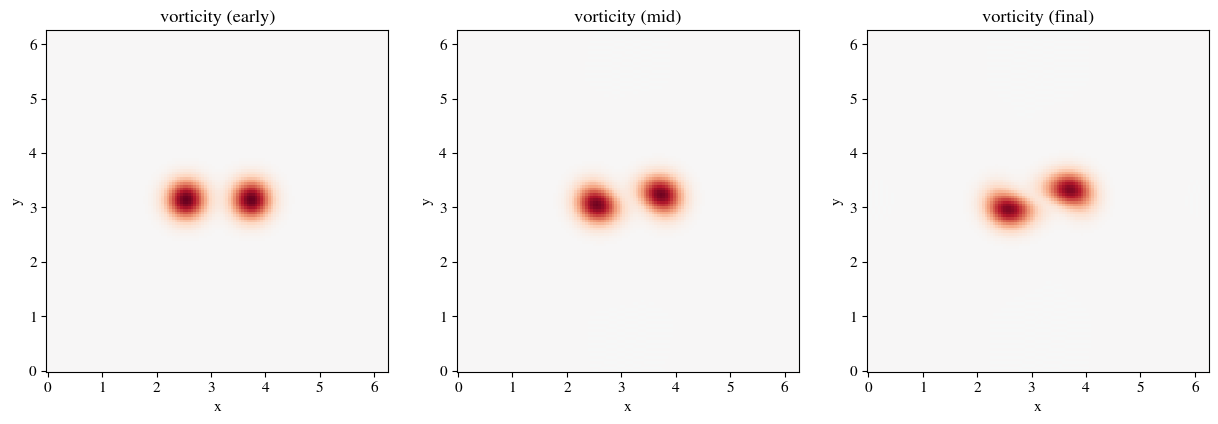

In [3]:
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
from pyutils import save_dual

def plot_vortex():
    vmax = float(np.abs(frames[0]).max())
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    for a, f, ttl in zip(ax, [frames[0], frames[len(frames) // 2], w],
                          ['early', 'mid', 'final']):
        a.pcolormesh(X, Y, f, cmap='RdBu_r', vmin=-vmax, vmax=vmax, shading='auto')
        a.set(title=f'vorticity ({ttl})', xlabel='x', ylabel='y')
        a.set_aspect('equal'); a.grid(False)

save_dual(plot_vortex, 'ns_vortex', FIG)
print('ns_vortex saved')

**Early** ($t\approx0$): two compact, equal-strength, well-separated circular cores sitting at $y\approx\pi$, centred near $x\approx2.5$ and $x\approx3.7$ — the initial Gaussians. **Mid** ($t\approx2$): the pair has rotated counter-clockwise about its midpoint and drawn closer, the cores beginning to lose their circular shape. **Final** ($t=4$): the two cores have spiralled into a tilted, diagonal orientation (lower-left and upper-right) and started to stretch and wrap into each other — the **merger in progress**, with the peak value diffused to $0.934$. Two like-signed vortices always co-rotate and coalesce; watching them do so while total circulation is preserved is the test that the vorticity solver is behaving.

**Hand-off.** As with the cavity, the per-step elliptic (here spectral) solve is the cost that the neural-operator (module 26) and reduced-order (module 19) surrogates aim to replace. We export the final field as a reference solution.

In [4]:
os.makedirs('../data', exist_ok=True)
np.savez('../data/vortex_reference.npz', X=X, Y=Y, omega=w, Re=2000.0)
print('saved ../data/vortex_reference.npz')

saved ../data/vortex_reference.npz


Writes `../data/vortex_reference.npz` with the grid `X, Y`, the final vorticity field `omega`, and `Re=2000.0` — the ground-truth snapshot the later surrogate notebooks train against and try to reproduce cheaply.